### 회귀 모델 (알고리즘)
- 회귀: 연속적인 수치(숫자)를 예측하는 모델
- 분류 VS 회귀
  - 분류: 범주(up/down)를 예측하며, 예측이 맞았는지/틀렸는지가 명확하다
    (혼동 행렬, 정확도 etc)
  - 회귀: 연속적인 수치(수익률)를 예측하며, 정확히 맞았다는 개념이 없다! > 오차의 크기를 측정 (MAE, RMSE, R^2 etc)

> **회귀에서는 얼마나 가까운가 (오차의 크기)** 가 가장 중요하다 \
> 참고: **로지스틱 회귀**는 이름만 회귀이고, 선형 계산 후 확률을 통해 범주를 판단하는 **분류 모델**이다!

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from _ml import build_dataset, time_split, FEATURES, SEED
from _style import setup

setup()
pd.set_option("display.width", 130)
df = build_dataset()
train, test, cutoff = time_split(df)

tr = train.sample(15000, random_state=SEED)
te = test.sample(4000, random_state=SEED)
X_train, X_test = tr[FEATURES], te[FEATURES]

# 정답(y)을 두 종류 준비 > 분류(target_up) / 회귀(target_ret)
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]      # 분류용 정답: 상승(1) / 하락(0)
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]    # 회귀용 정답: 수익률(수치)
print(f"학습 {len(tr):,}행 ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f"테스트 {len(te):,}행 ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f"피처 {len(FEATURES)}개")
print(f"・분류용 정답(target_up): {y_train_cls.unique()} (범주)")
print(f"・회귀용 정답(target_ret): {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f} (수치)")

학습 15,000행 (2023-10-24 ~ 2026-01-16)
테스트 4,000행 (2026-01-19 ~ 2026-09-07)
피처 7개
・분류용 정답(target_up): [0 1] (범주)
・회귀용 정답(target_ret): -0.2260 ~ 0.2313 (수치)


- 분류: y = target_up (0/1) >> RandomForestClassifier
- 회귀: y = target_ret (수익률) >> RandomForestRegressor

**이름은 동일한 알고리즘이지만 평가 방법이 완전히 달라진다**
- RandomForestClassifier > accuracy_score(정확도), f1_score(f1 점수)
- RandomForestRegressor > mean_absolute_error(MAE), mean_squared_error(MSE), r2_score(R^2)

In [44]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor                                  # 분류 / 회귀 랜덤 포레스트 모델
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score)   # 분류(정확도, F1) / 회귀(MAE, MSE, R^2) 평가 지표

clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)

# 학습 >> fit(X,y)
# 분류 모델 학습
clf.fit(X_train, y_train_cls)
# 회귀 모델 학습
reg.fit(X_train, y_train_reg)
# 예측 >> pred = predict(X_test)
# 분류 모델 예측 (pred_cls)
pred_cls = clf.predict(X_test)
# 회귀 모델 예측 (pred_reg)
pred_reg = reg.predict(X_test)

print(f"{'':<14}{'분류':<32}{'회귀'}")
print("-" * 40) # ------------------------------------------------------
print(f"{'정답 예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측 예시':<13}{pred_cls[0]:<32}{pred_reg[0]:.4f}")
print("-" * 40) # ------------------------------------------------------
print(f"분류 평가: 정확도 {accuracy_score(y_test_cls, pred_cls):.4f}"
      f" / F1 {f1_score(y_test_cls, pred_cls):.4f}")
print(f"회귀 평가: RMSE {np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.4f}"
      f" / R^2 {r2_score(y_test_reg, pred_reg):.4f}")

              분류                              회귀
----------------------------------------
정답 예시        0                               -0.0068
예측 예시        1                               -0.0000
----------------------------------------
분류 평가: 정확도 0.4933 / F1 0.4269
회귀 평가: RMSE 0.0274 / R^2 -0.0068


In [45]:
# 회귀 예측을 0을 기준으로 나누어서 분류를 해본다면？
reg_to_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델 예측을 0 기준으로 나눈 정확도: "
      f"{accuracy_score(y_test_cls, reg_to_cls):.4f}")
print(f"분류 모델로 학습한 정확도: "
      f"{accuracy_score(y_test_cls, pred_cls):.4f}")

회귀 모델 예측을 0 기준으로 나눈 정확도: 0.4793
분류 모델로 학습한 정확도: 0.4933


---
### LinearRegression (선형 회귀)
가장 단순한 선형 회귀 모델・직선으로 관계를 표현 \
`예측한 값 = w1*ret_1d + w2*ret_5d + ... + b`

- 학습: **오차의 제곱합(MSE)** 이 가장 작아지는 가중치(w)와 절편(b)를 찾는 것
  - w = 가중치(계수): 다른 피처가 그대로일 때 해당 피처가 1 증가하면 예측값이 얼마나 변하는지
  - b = 절편(편향)

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler    # 각 피처의 평균을 0、표준 편차를 1로 맞춰준다

# [TIP] Pipeline 은 fit 할 때 학습 데이터로만 스케일러 기준(평균, 표준편차)을 계산해서, 테스트 데이터 정보가 섞이는 '전처리 누수'를 자동으로 막아준다
def make(model):
    return Pipeline([("sc", StandardScaler()), ("m", model)])
lin = make(LinearRegression())
lin.fit(X_train, y_train_reg)

# 절편(b), 계수(w) 확인
coef = pd.Series(lin.named_steps["m"].coef_, index=FEATURES).sort_values()
    # lin.named_steps["m"]: 모델 객체 추출
    # 모델.coef_ : 가중치(계수) 배열
intercept = lin.named_steps["m"].intercept_
    # 모델.intercept_ : 절편(편향) 값
print(f"절편(b): {intercept:.6f}")
print("-" * 40) # ------------------------------------------------------
print(f"가중치 (w): ")
print(coef.round(6).to_string())

절편(b): -0.000063
----------------------------------------
가중치 (w): 
vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756


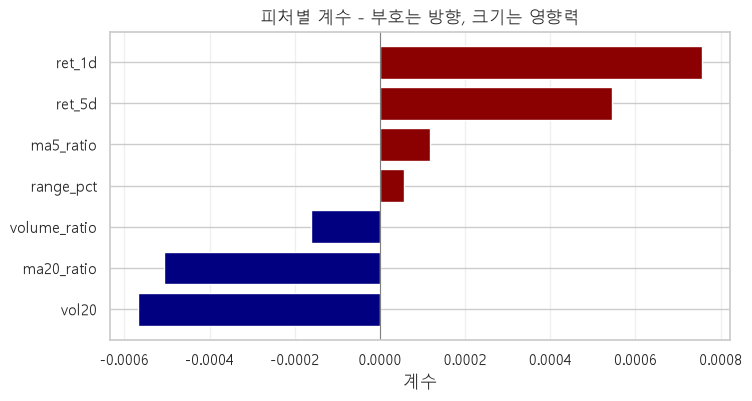

In [47]:
fig, ax = plt.subplots(figsize=(8,4))
colors = ["Navy" if v < 0 else "Darkred" for v in coef.values]

ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("계수")
ax.set_title("피처별 계수 - 부호는 방향, 크기는 영향력")
ax.grid(alpha=0.3, axis="x")

plt.show()

**계수(가중치)는 해석을 도와주는 지표**
> 계수의 부호는 방향 (+ 올리는 쪽・- 내리는 쪽)을 절대값은 영향력의 크기를 알려준다 \
> 다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 한다 \
> 또한 피처끼리 서로 비슷하다면 (다중 공선성) 계수가 불안정해져서 해석이 틀어질 수 있다 \
> (우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로、선형 관계가 거의 없다고 볼 수 있다)

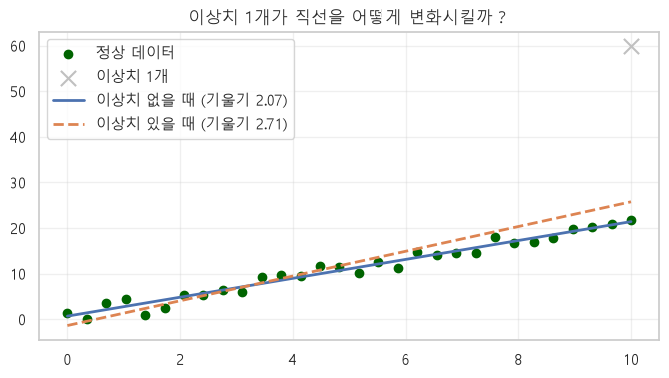

In [48]:
# 이상치를 하나 넣어서 직선의 변화를 확인해보기
rng = np.random.default_rng(SEED)       # 난수 생성기
x_demo = np.linspace(0, 10, 30)         # 0 ~ 10 구간을 균등하게 나눈 30개의 숫자
    #「y = 2x + 1」에 노이즈 추가 (평균 0, 표준편차 1.5인 오차 30개)
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

# 이상치 1개 추가: x=10 인데, y=60 (원래대로라면 21 근처 값이어야 한다)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(x_demo, y_demo, label="정상 데이터", color="Darkgreen")
ax.scatter([10], [60], s=120, label="이상치 1개", color="Silver", marker="x", zorder=5)
datas = [
    (x_demo, y_demo, "-", "이상치 없을 때"),
    (x_bad, y_bad, "--", "이상치 있을 때")
]
# [TIP] 이상치에 강한 회귀가 필요하면 sklearn.linear_model.HuberRegressor 처럼 큰 오차의 영향을 줄여주는 모델을 사용할 수 있다
for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1, 1), ys)
    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1, 1)), d, lw=2, label=f"{name} (기울기 {m.coef_[0]:.2f})")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("이상치 1개가 직선을 어떻게 변화시킬까？")
plt.show()

**이상치 하나가 직선을 끌고가는 것을 확인할 수 있다**
> 선형 회귀는 오차의 제곱을 최소화한다 \
> 크게 빗나간 데이터(이상치)가 제곱되면서 영향력이 매우 커진다!

### 규제 회귀 - Ridge, Lasso, ElasticNet
> 피처가 많아지면 모델이 학습 데이터의 잡음까지 외우게 되고, 계수가 비정상적으로 커지면서 과적합이 일어나게 된다 \
> 규제는 **계수가 커지는 것에 벌점** 을 줘서 이를 막는 방법 \
`비용 = 오차(MSE) + 벌점` (절편 b는 벌점 대상이 아니다)
---
||Ridge(L2)|Lasso(L1)|ElasticNet|
|:--:|:--:|:--:|:--:|
|벌점|계수의 제곱합|계수의 절대값 합|둘을 섞는다(`l1_ratio`로 비율 조절)|
|효과|계수를 골고루 작게|덜 중요한 계수를 0으로|중간|
|결과|모든 피처를 유지 (0이 되지 않는다)|피처 선택 효과|상관된 피처가 많을 때 유용하다|

> **Caution** : 동일한 `alpha`를 사용한다고 해서 Ridge와 Lasso의 규제 세기가 동일하지 않다 \
> (내부 구현 오차 항 배율이 다르다)

In [49]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
models = {
    "Linear": make(LinearRegression()),                             # 규제가 없는 기본 선형 회귀
    "Ridge": make(Ridge(alpha=1.0)),                                # 규제가 약한 Ridge > 계수를 조금 줄인 모델
    "Ridge(a=1000)": make(Ridge(alpha=1000.0)),                     # 규제가 강한 Ridge > 계수를 많이 줄인 모델
    "Lasso(a=1e-4)": make(Lasso(alpha=1e-4)),                       # 규제가 약한 Lasso > 일부 계수만 0
    "Lasso(a=1e-3)": make(Lasso(alpha=1e-3)),                       # 규제가 강한 Lasso > 불필요한 계수를 0
    "ElasticNet": make(ElasticNet(alpha=1e-4, l1_ratio=0.5))        # L1_ratio=0.5 : Lasso와 Ridge 벌점을 반반
}

coef_table = {}
for name, m in models.items():
    m.fit(X_train, y_train_reg)
    coef_table[name] = m.named_steps["m"].coef_

coef_df = pd.DataFrame(coef_table, index=FEATURES)
# [TIP] 적절한 alpha 는 RidgeCV / LassoCV(alphas=[...]) 를 사용하면 교차 검증으로 자동 선택할 수 있다
print(coef_df.round(6).to_string())
print("-" * 40) # ------------------------------------------------------

for col in ["Lasso(a=1e-4)", "Lasso(a=1e-3)"]:
    zero_features = [f for f, v in coef_df[col].items() if v == 0]
    print(f"{col:<16} 0이 된 피처 ({len(zero_features)}개): {zero_features}")

                Linear     Ridge  Ridge(a=1000)  Lasso(a=1e-4)  Lasso(a=1e-3)  ElasticNet
ret_1d        0.000756  0.000756       0.000657       0.000659            0.0    0.000707
ret_5d        0.000544  0.000544       0.000380       0.000132            0.0    0.000339
ma5_ratio     0.000117  0.000117       0.000235       0.000133            0.0    0.000124
ma20_ratio   -0.000507 -0.000506      -0.000392      -0.000058            0.0   -0.000282
vol20        -0.000567 -0.000567      -0.000528      -0.000460            0.0   -0.000510
volume_ratio -0.000161 -0.000161      -0.000151      -0.000058            0.0   -0.000107
range_pct     0.000055  0.000055       0.000046       0.000000            0.0    0.000000
----------------------------------------
Lasso(a=1e-4)    0이 된 피처 (1개): ['range_pct']
Lasso(a=1e-3)    0이 된 피처 (7개): ['ret_1d', 'ret_5d', 'ma5_ratio', 'ma20_ratio', 'vol20', 'volume_ratio', 'range_pct']


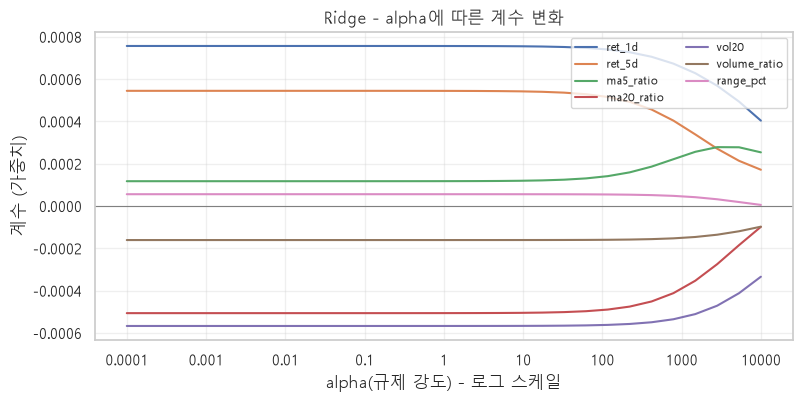

In [50]:
# alpha를 키우면 계수가 어떻게 줄어드는 지 확인해보기
# 0.0001 ~ 10000 구간을 로그 스케일 간격으로 30개로 나눈다
alphas = np.logspace(-4, 4, 30)
path = []
for a in alphas:
    m = make(Ridge(alpha=a))
    m.fit(X_train, y_train_reg)
    path.append(m.named_steps["m"].coef_)
path = np.array(path)
    # list > array
fig, ax = plt.subplots(figsize=(9,4))
for i, f in enumerate(FEATURES):
    ax.plot(alphas, path[:, i], label=f)

ax.set_xscale("log")
# 로그 축 눈금(10^-4)의 마이너스 기호(U+2212)가 한글 폰트에 없어서 경고가 반복되므로, 눈금을 일반 숫자(0.0001)로 표시한다
import matplotlib.ticker as mticker
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("alpha(규제 강도) - 로그 스케일")
ax.set_ylabel("계수 (가중치)")
ax.set_title("Ridge - alpha에 따른 계수 변화")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.show()

**alpha(규제 강도)를 너무 키우면 과소적합 된다** \
> 규제가 강해질수록 계수가 전부 0에 가까워지고、모델은 사실상 아무것도 학습하지 못했다 \
> (그래프에서도 계수가 0으로 수렴한다)
- 적절한 alpha 값은 데이터마다 다르다

**Lasso는 피처를 골라준다** \
> 불필요한 피처의 계수를 아예 0으로 만들어 모델에서 제외한다
> 위 표에서 alpha=1e-4일 때, `range_pct` 1개만 제외되었지만 alpha=1e-3일 때는 7개의 피처가 모두 제외되었다
- 이번 데이터 기준으로 alpha=1e-3부터는 규제가 너무 강해서 "아무것도 쓰지 못하고 평균만 예측하는 모델"이 되었다!

**alpha 값은 타깃(y)과 계수의 크기에 맞춰서 정해야한다** \
> (수익률처럼 y값이 아주 작은 데이터는 alpha 값도 작게 잡아야 한다)
---

### KNN 회귀와 RandomForest 회귀
#### KNN
> **KNeighborsClassifier** > 주변 k개의 다수결로 범주 결정 \
> **KNeighborsRegressor** > 주변 k개의 **평균**으로 수치 결정

#### RandomForest
> **RandomForestClassifier** > 트리들의 다수결 \
> **RandomForestRegressor** > 트리들의 예측값의 **평균**
- 스케일링은 거리 기반인 KNN에게 필요하고, 트리 계열은 필요없다!

In [51]:
from sklearn.neighbors import KNeighborsRegressor

models = {
    "기본값(평균)": None,
    "Linear": make(LinearRegression()),
    "Ridge(a=1.0)": make(Ridge(alpha=1.0)),
    "Lasso(a=1e-4)": make(Lasso(alpha=1e-4)),
    "KNN(k=50)": make(KNeighborsRegressor(n_neighbors=50, n_jobs=-1)),
    "RandomForest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED, max_depth=6)
}
rows = []   # 모델별 평가 지표
preds = {}  # 모델별 예측 결과 (아래 반복문에서 preds 로 사용)

for name, m in models.items():
    if m is None:
        # 학습 데이터의 평균만으로 직접 예측 (비교 기준선)
        # [TIP] 기준선 모델은 sklearn.dummy.DummyRegressor(strategy='mean') 으로도 만들 수 있다 (03 노트북의 DummyClassifier 와 같은 역할)
        p = np.full(len(y_test_reg), y_train_reg.mean())   # 결과를 p 에 저장해야 아래에서 사용할 수 있다
        r2_train = 0.0
    else:
        m.fit(X_train, y_train_reg)
        p = m.predict(X_test)
        r2_train = m.score(X_train, y_train_reg)        # 회귀 모델에서는 R² 반환 (학습 데이터 기준)

    preds[name] = p
    rows.append({
        "모델": name,
        "MAE": mean_absolute_error(y_test_reg, p),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, p)),
        "R² (테스트)": r2_score(y_test_reg, p),
        "R² (학습용)": r2_train
    })
print(pd.DataFrame(rows).round(6).to_string())

              모델       MAE      RMSE  R² (테스트)  R² (학습용)
0        기본값(평균)  0.017888  0.027297 -0.000001  0.000000
1         Linear  0.017925  0.027317 -0.001506  0.001950
2   Ridge(a=1.0)  0.017925  0.027317 -0.001506  0.001950
3  Lasso(a=1e-4)  0.017922  0.027313 -0.001204  0.001777
4      KNN(k=50)  0.018125  0.027621 -0.023880  0.024733
5   RandomForest  0.017967  0.027389 -0.006779  0.051433


### R² = 1 - (모델의 오차 제곱합) / (평균으로 예측했을 때의 오차 제곱합)
|R²|의미|
|:--:|:--:|
|1.0|완벽|
|0.7|타깃 변동(분산)의 70%|
|0.0|평균으로 찍은 것과 동일하다|
|음수|평균으로 찍은 것보다 좋지 않다|

- 평균으로 예측한 결과를 기준으로 **다른 모델이 이 기준선보다 좋은지**를 판단해야 한다
- 위의 결과를 보면 이번 데이터에서는 어떤 모델도 평균 기준선보다 좋은 지표를 만들지 못했다 (R² 테스트 기준)
  - 또한, 랜덤-포레스트는 학습 R²이 테스트 R²보다 굉장히 높아서 학습 데이터의 잡음을 일부 외운 **"과적합"** 신호로 볼 수 있다
---

### 평균 지표: MAE, MSE, RMSE, R²
> 회귀 모델의 평가 지표는 모두 **오차(실제값-예측값)** 를 가지고 구한 값들이다

> 1. MAE: 오차 절대값의 평균、해석이 직관적이고 이상치에 덜 민감하다
> 2. MSE: 오차 제곱의 평균、큰 오차에 큰 벌점・단위가 제곱이라 해석이 어렵다
> 3. RMSE: MSE의 제곱근、MSE의 장점 + 기존 단위로 해석이 가능하다
> 4. R²: 평균으로 찍을 때 대비 모델 점수、단위가 없어서 모델 간 비교 시 유용하다

> 결과 보고 시 **MAE**, **RMSE**, **R²** 지표들로 함께 보고하자 \
> R²는 단위가 없기 때문에 같은 데이터에서 모델끼리 비교하기는 좋지만 얼마만큼의 차이가 있는지는 설명하기가 어렵다 \

### 잔차 분석
`residual = y_test - pred`

In [52]:
pred_rf = preds["RandomForest"]
residual = y_test_reg.values - pred_rf

print("잔차 = 실제값 - 예측값")
print(f"평균: {residual.mean():>12.6f}")
print(f"표준편차: {residual.std():>12.6f}")
print(f"최소: {residual.min():12.6f}")
print(f"최대: {residual.max():12.6f}")

잔차 = 실제값 - 예측값
평균:     0.000095
표준편차:     0.027389
최소:    -0.204308
최대:     0.205061


> 잔차 평균이 0에 가깝다는 것은 어느 한 쪽으로 쏠려서 예측하지는 않았다는 것을 의미한다 \
> 다만, 평균이 0이라고 해서 잘 맞추는 모델을 의미하지는 않는다

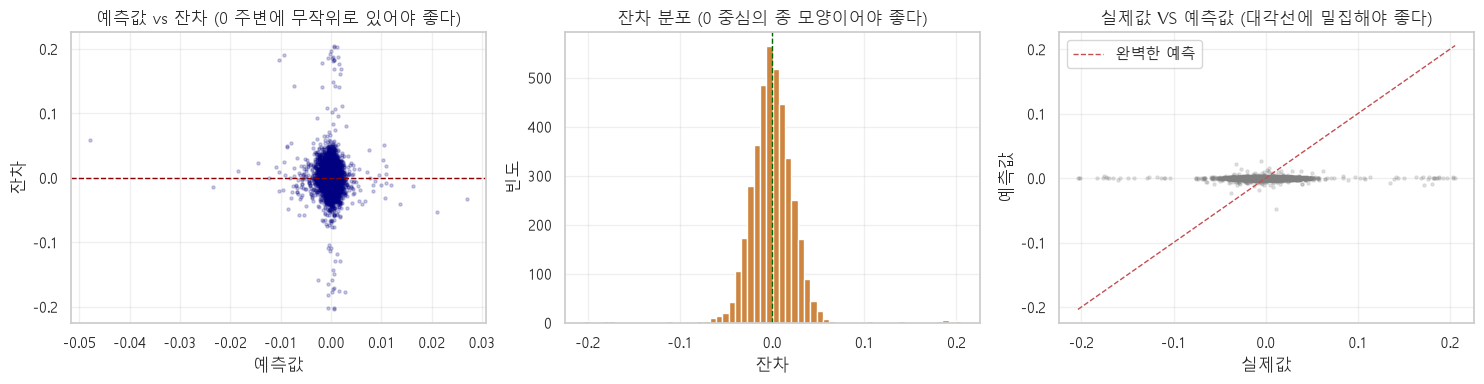

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. 예측값 vs 잔차
axes[0].scatter(pred_rf, residual, s=5, alpha=0.2, color="Navy")
axes[0].axhline(0, color="DarkRed", ls="--", lw=1)
axes[0].set_xlabel("예측값")
axes[0].set_ylabel("잔차")
axes[0].set_title("예측값 vs 잔차 (0 주변에 무작위로 있어야 좋다)")
axes[0].grid(alpha=0.3)

# 2. 잔차 히스토그램
axes[1].hist(residual, bins=60, color="Peru")             # "DarkBronze" 는 matplotlib 에 없는 색 이름 (ValueError)
axes[1].axvline(0, color="DarkGreen", ls="--", lw=1)
axes[1].set_xlabel("잔차")
axes[1].set_ylabel("빈도")
axes[1].set_title("잔차 분포 (0 중심의 종 모양이어야 좋다)")
axes[1].grid(alpha=0.3)

# 3. 실제 값 VS 예측 값
axes[2].scatter(y_test_reg, pred_rf, s=5, alpha=0.2, color="Gray")   # S 는 정의되지 않은 변수, "WhiteGray" 는 없는 색 이름
lo, hi = y_test_reg.min(), y_test_reg.max()
axes[2].plot([lo, hi], [lo, hi], "r--", lw=1, label="완벽한 예측")
axes[2].set_xlabel("실제값")
axes[2].set_ylabel("예측값")
axes[2].set_title("실제값 VS 예측값 (대각선에 밀집해야 좋다)")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

**3번째 그래프 (실제값 VS 예측값)** 을 보면, 실제값은 -0.2 ~ 0.2 범위로 넓게 퍼져 있는데 예측 값은 전부 0 근처에 몰려있다 \
- 이것은 "모델이 거의 설명하지 못한다"는 것을 보여주고 있다
- 모델이 사실상 평균 근처만 예측하고 있다
- RMSE가 실제 수익률의 표준편차와 거의 같다는 숫자로도 확인할 수 있다